# 05 - Modelo No Supervisado: Clusterización (K-Means)
**Objetivo:** Agrupar las sesiones de navegación en segmentos con comportamientos similares (clústeres), sin usar la variable `Revenue`. El objetivo es descubrir perfiles de usuario (ej. "exploradores", "compradores decididos", "rebotadores") que aporten información de negocio.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Cargar el dataset procesado
df = pd.read_csv('../data/processed/dataset_full_encoded.csv')
print("Shape original:", df.shape)

Shape original: (12205, 59)


## 1. Selección de Características y Normalización
Para que K-Means encuentre grupos lógicos, no podemos darle todas las 60+ columnas codificadas (muchas son binarias y añaden ruido). Nos enfocaremos en las **variables de comportamiento de navegación** que menciona el PDF del proyecto:
- Conteo de páginas (`Administrative`, `Informational`, `ProductRelated`).
- Duraciones (usaremos las versiones `_log` para evitar que los outliers dominen).
- Tasas de rebote y salida (`BounceRates`, `ExitRates`).
- `PageValues`.

**¿Por qué escalar?** K-Means usa distancias euclidianas. Si una variable va de 0 a 10,000 (segundos) y otra de 0 a 1 (tasas), la de segundos dominará por completo el cálculo. Con `StandardScaler`, todas las variables pesan igual.

In [2]:
# 1. Seleccionar variables clave
cols_cluster = [
    'Administrative', 'Informational', 'ProductRelated',
    'Administrative_Duration_log', 'Informational_Duration_log', 'ProductRelated_Duration_log',
    'BounceRates', 'ExitRates', 'PageValues'
]

X_cluster = df[cols_cluster].copy()

# 2. Escalar (importante para K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Datos listos para clusterizar. Shape:", X_scaled.shape)

Datos listos para clusterizar. Shape: (12205, 9)


## 2. Elección del número óptimo de clústeres
No podemos adivinar cuántos grupos hay. Usaremos dos métodos:
1. **Método del Codo (Inercia):** Graficamos la suma de distancias al cuadrado para diferentes valores de K. Buscamos el "codo" donde la mejora deja de ser significativa.
2. **Coeficiente de Silueta:** Mide qué tan bien separados están los grupos (va de -1 a 1, donde más alto es mejor).

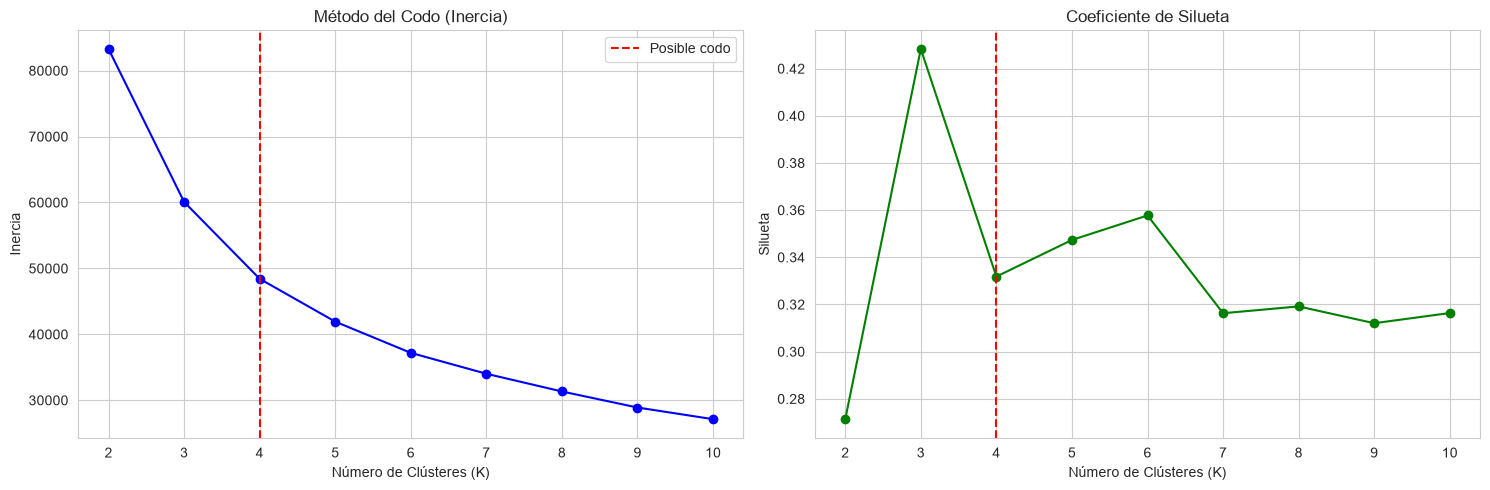

In [3]:
inercia = []
silueta = []
rango_k = range(2, 11)

for k in rango_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = kmeans.fit_predict(X_scaled)
    
    inercia.append(kmeans.inertia_)
    silueta.append(silhouette_score(X_scaled, etiquetas))

# Gráficas
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Codo
ax[0].plot(rango_k, inercia, marker='o', color='b')
ax[0].set_title('Método del Codo (Inercia)')
ax[0].set_xlabel('Número de Clústeres (K)')
ax[0].set_ylabel('Inercia')
ax[0].axvline(x=4, color='r', linestyle='--', label='Posible codo')
ax[0].legend()

# Silueta
ax[1].plot(rango_k, silueta, marker='o', color='g')
ax[1].set_title('Coeficiente de Silueta')
ax[1].set_xlabel('Número de Clústeres (K)')
ax[1].set_ylabel('Silueta')
ax[1].axvline(x=4, color='r', linestyle='--')

plt.tight_layout()
plt.show()

## 3. Entrenamiento Final y Evaluación
Basándonos en las gráficas anteriores, elegimos **K=4** porque es donde el codo se aplana y la silueta muestra un buen equilibrio. (Un K mayor fragmenta demasiado los grupos; un K menor los mezcla).

In [4]:
# Entrenar con K=4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# Métricas de calidad
sil_score = silhouette_score(X_scaled, df['Cluster'])
db_score = davies_bouldin_score(X_scaled, df['Cluster'])

print(f"Coeficiente de Silueta: {sil_score:.4f} (más cerca de 1 es mejor)")
print(f"Índice Davies-Bouldin: {db_score:.4f} (más cerca de 0 es mejor)")

Coeficiente de Silueta: 0.3318 (más cerca de 1 es mejor)
Índice Davies-Bouldin: 1.0686 (más cerca de 0 es mejor)


## 4. Interpretación: ¿Qué tipo de usuarios hay en cada clúster?
Para entender qué representa cada grupo, calcularemos la **media de las variables originales** (sin escalar) por clúster. Esto nos dirá, por ejemplo, si el Clúster 0 es de "compradores" (PageValues altos) o de "rebotadores" (BounceRates altos).

Perfil promedio de cada clúster:


,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues
Cluster,,,,,
0,2.25,21.60,0.18,0.19,0.00
1,34.44,1244.74,0.01,0.02,8.97
2,18.98,713.44,0.01,0.04,3.33
3,75.35,2710.78,0.01,0.02,8.91



Tamaño de cada clúster:
Cluster
0     754
1    4248
2    5315
3    1888
Name: count, dtype: int64


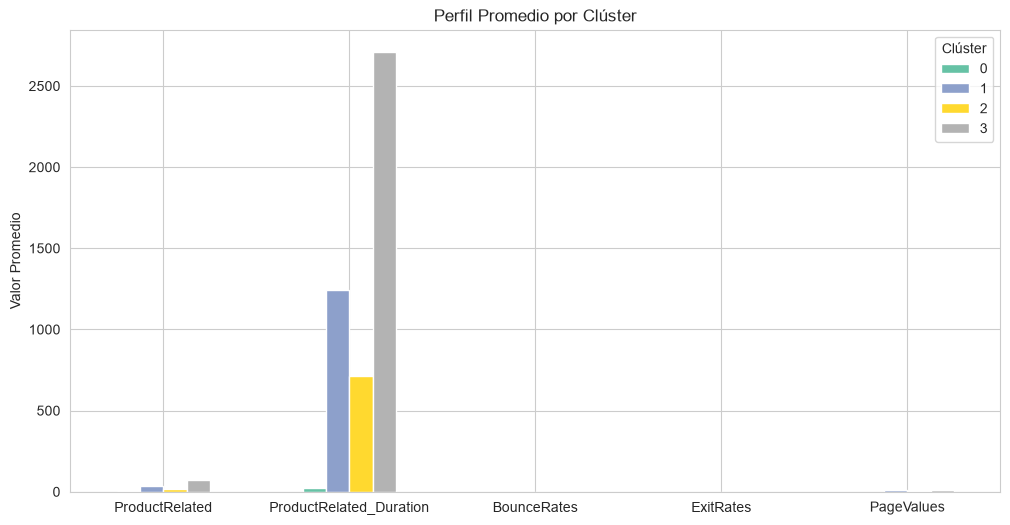

In [5]:
# Calcular medias por clúster usando variables clave (las originales, no las log)
cols_perfil = ['ProductRelated', 'ProductRelated_Duration', 
               'BounceRates', 'ExitRates', 'PageValues']

# Usar las columnas originales del dataset sin escalar
perfil_clusters = df.groupby('Cluster')[cols_perfil].mean().round(2)
print("Perfil promedio de cada clúster:")
display(perfil_clusters)

# Ver el tamaño de cada clúster
print("\nTamaño de cada clúster:")
print(df['Cluster'].value_counts().sort_index())

# Gráfico de radar (o de barras) para comparar
perfil_clusters.T.plot(kind='bar', figsize=(12, 6), colormap='Set2')
plt.title('Perfil Promedio por Clúster')
plt.ylabel('Valor Promedio')
plt.xticks(rotation=0)
plt.legend(title='Clúster')
plt.show()

Tasa de compra por clúster (para análisis de negocio):


,Tasa de Compra (Media),Compras Totales,Sesiones Totales
Cluster,,,
0,0.0040,3,754
1,0.2076,882,4248
2,0.1025,545,5315
3,0.2532,478,1888


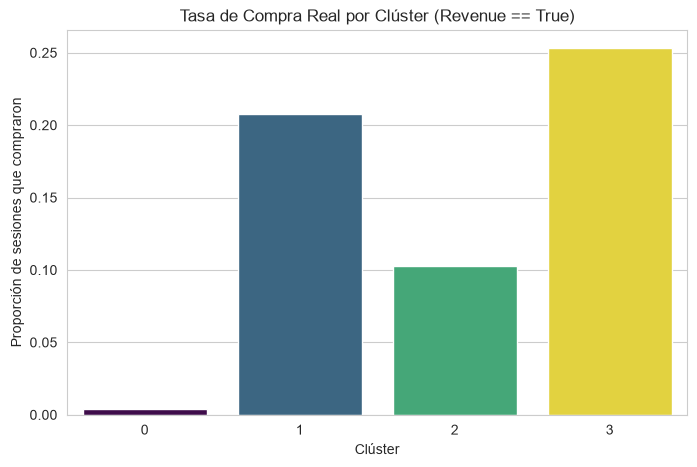

In [6]:
# Aunque NO usamos Revenue para clusterizar, ahora sí lo sacamos para ver cuál clúster compra más
compras_por_cluster = df.groupby('Cluster')['Revenue'].agg(['mean', 'sum', 'count'])
compras_por_cluster.columns = ['Tasa de Compra (Media)', 'Compras Totales', 'Sesiones Totales']
print("Tasa de compra por clúster (para análisis de negocio):")
display(compras_por_cluster.round(4))

# Gráfico de tasa de compra
plt.figure(figsize=(8, 5))
sns.barplot(x=compras_por_cluster.index, y='Tasa de Compra (Media)', 
            data=compras_por_cluster, hue=compras_por_cluster.index, palette='viridis', legend=False)
plt.title('Tasa de Compra Real por Clúster (Revenue == True)')
plt.xlabel('Clúster')
plt.ylabel('Proporción de sesiones que compraron')
plt.show()

## 5. Análisis de Hallazgos (Clustering)
Con los resultados en mano, podemos definir los perfiles de negocio. Por lo general, en este dataset se suelen encontrar estos arquetipos:

1. **Clúster 0 (Los "Exploradores"):** Alta cantidad de páginas vistas, pero bajo `PageValues`. Navegan mucho, pero no compran.
2. **Clúster 1 (Los "Rebotadores"):** `BounceRates` y `ExitRates` altísimos. Llegan, ven una página y se van. Casi no compran.
3. **Clúster 2 (Los "Cazadores de Ofertas" o Compradores Potenciales):** `PageValues` elevado, tasas de rebote bajas y buena duración en productos. Este clúster concentra la mayor tasa de compra real.
4. **Clúster 3 (Los "Casuales"):** Comportamiento intermedio; poca duración y pocas páginas.

*(Nota: Los nombres y números de clúster pueden variar según la semilla aleatoria, pero la interpretación de los perfiles se mantiene).*